In [1]:
import wot
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scanpy as sc
from pathlib import Path
from collections import defaultdict
from scipy import sparse

import sys
from pathlib import Path

_start = Path.cwd().resolve()
_repo_root = next((p for p in [_start, *_start.parents] if (p / "chronopack").exists()), _start)
if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))

from chronopack.trajectories import (
    CalculateTerminalFatesAcrossCells,
    PlotHardClusterMassProportionsOverTime,
    build_transition_matrices,
    cosine_topk_leiden_from_terminal_dist,
    embed_block,
    extract_wot_couplings,
    fate_umap_2x2_scanpy,
    keep_topk,
    mass_retention_plots_and_umap,
    run_wot_transport_workflow,
    read_tmap,
    sparse_adjacency_from_tmats,
    terminal_fates_from_terminal_clusters,
    topk_csr_rows,
)


# Function definitions

## Waddington‑OT (Transport maps)
Following the official [WOT notebooks](https://github.com/broadinstitute/wot/tree/master/notebooks), we compute transport maps between successive time points.
Make sure `adata.obs['time']` (integer or float) exists and reflects the sampling time in *hours/days* used in the Seurat notebook.

In [2]:
adata = sc.read_h5ad('../output/adata_full.chk0.h5ad')
adata_hvg = sc.read_h5ad('../output/adata_hvg.chk0.h5ad')
adata.obs['time'] = pd.to_numeric(adata.obs['time'].astype(str))
adata_hvg.obs['time'] = pd.to_numeric(adata_hvg.obs['time'].astype(str))
adata_hvg.X = adata_hvg.layers['log1p']

adata_hvg_thp1 = adata_hvg[adata_hvg.obs['cell_type'] == 'THP1', :].copy()
adata_hvg_k562 = adata_hvg[adata_hvg.obs['cell_type'] == 'K562', :].copy()

wot_thp1 = run_wot_transport_workflow(
    adata_hvg_thp1,
    tmap_dir='../intmd/tmaps.THP1.SingleCell/',
    ot_model_kwargs=dict(epsilon=0.05, lambda1=1, lambda2=50, growth_iters=3, day_field='time'),
    compute_transport_maps=True,
    transition_topk=30,
    symmetrize='maximum',
    attach_graph=False,
)

wot_k562 = run_wot_transport_workflow(
    adata_hvg_k562,
    tmap_dir='../intmd/tmaps.K562.SingleCell/',
    ot_model_kwargs=dict(epsilon=0.05, lambda1=1, lambda2=50, growth_iters=3, day_field='time'),
    compute_transport_maps=True,
    transition_topk=30,
    symmetrize='maximum',
    attach_graph=False,
)


Built 11 transport matrices.


Built 11 transport matrices.


In [3]:
transitions_long = {'THP1': wot_thp1['transitions_long'], 'K562': wot_k562['transitions_long']}
tmaps = {'THP1': wot_thp1['tmaps'], 'K562': wot_k562['tmaps']}
tmats = {'THP1': wot_thp1['tmats'], 'K562': wot_k562['tmats']}


# Construct forward transition kernel (+ pruned & symmetric variants)

In [4]:
T_full_thp1, T_pruned_thp1, T_sym_thp1 = wot_thp1['T_full'], wot_thp1['T_pruned'], wot_thp1['T_sym']
T_full_k562, T_pruned_k562, T_sym_k562 = wot_k562['T_full'], wot_k562['T_pruned'], wot_k562['T_sym']


In [5]:
thp1_cells = adata_hvg_thp1.obs.index
k562_cells = adata_hvg_k562.obs.index
obs_index = pd.Index(adata_hvg.obs.index)

assert len(thp1_cells.intersection(k562_cells)) == 0
assert len(thp1_cells.difference(obs_index)) == 0
assert len(k562_cells.difference(obs_index)) == 0

n = adata_hvg.n_obs
pos_thp1 = obs_index.get_indexer(thp1_cells)
pos_k562 = obs_index.get_indexer(k562_cells)

T_full = embed_block(T_full_thp1, pos_thp1, n) + embed_block(T_full_k562, pos_k562, n)
T_pruned = embed_block(T_pruned_thp1, pos_thp1, n) + embed_block(T_pruned_k562, pos_k562, n)

print(T_full_thp1.shape)
print(T_full_k562.shape)
print(T_full.shape)


(787, 787)
(3128, 3128)
(3915, 3915)


In [6]:
# Build the combined THP1+K562 graph from the two cell-type-specific WOT kernels.
T_sym = 0.5 * (T_pruned + T_pruned.T)

adata_hvg.obsp['ot_graph'] = T_sym
adata_hvg.uns['ot_graph'] = {
    'connectivities_key': 'ot_graph',
    'distances_key': 'ot_graph',
    'params': {'method': 'WOT_tmats_per_cell_type', 'top_k': 30, 'symmetric': 'mean'},
}

key = 'X_ot_umap'
sc.tl.umap(adata_hvg, neighbors_key='ot_graph', init_pos='spectral', copy=False, random_state=1, min_dist=1.5, spread=1.5)
adata_hvg.obsm[key] = adata_hvg.obsm['X_umap'].copy()


# Old trajectory clustering

In [7]:
# Diagnostic trajectory clustering: successor-representation graph, resolution 0.5.
# This label is retained as traj_leiden_sr for comparison/plots; the downstream
# tradeSeq input generation uses the final traj_clusters labels below.
P = T_pruned.tocsr().astype(float)
rs = np.asarray(P.sum(axis=1)).ravel(); rs[rs==0] = 1.0
P = sp.diags(1/rs) @ P

K, gamma = 12, 0.9
S, Pk, w = sp.csr_matrix(P.shape), P.copy(), gamma
for _ in range(1, K+1):
    S += w * Pk
    Pk = Pk @ P
    w *= gamma

W = 0.5 * (S + S.T)
W.setdiag(1e-12)
W.eliminate_zeros()

sc.tl.leiden(
    adata_hvg,
    adjacency=W.tocsr(),
    directed=False,
    use_weights=True,
    key_added='traj_leiden_sr',
    resolution=0.5,
)


/new-stg/home/alex/.tmp/ipykernel_1037662/3491580244.py:19: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


In [8]:
adata.obsm = adata_hvg.obsm.copy()
adata.obsp = adata_hvg.obsp.copy()
adata.obs = adata_hvg.obs.copy()

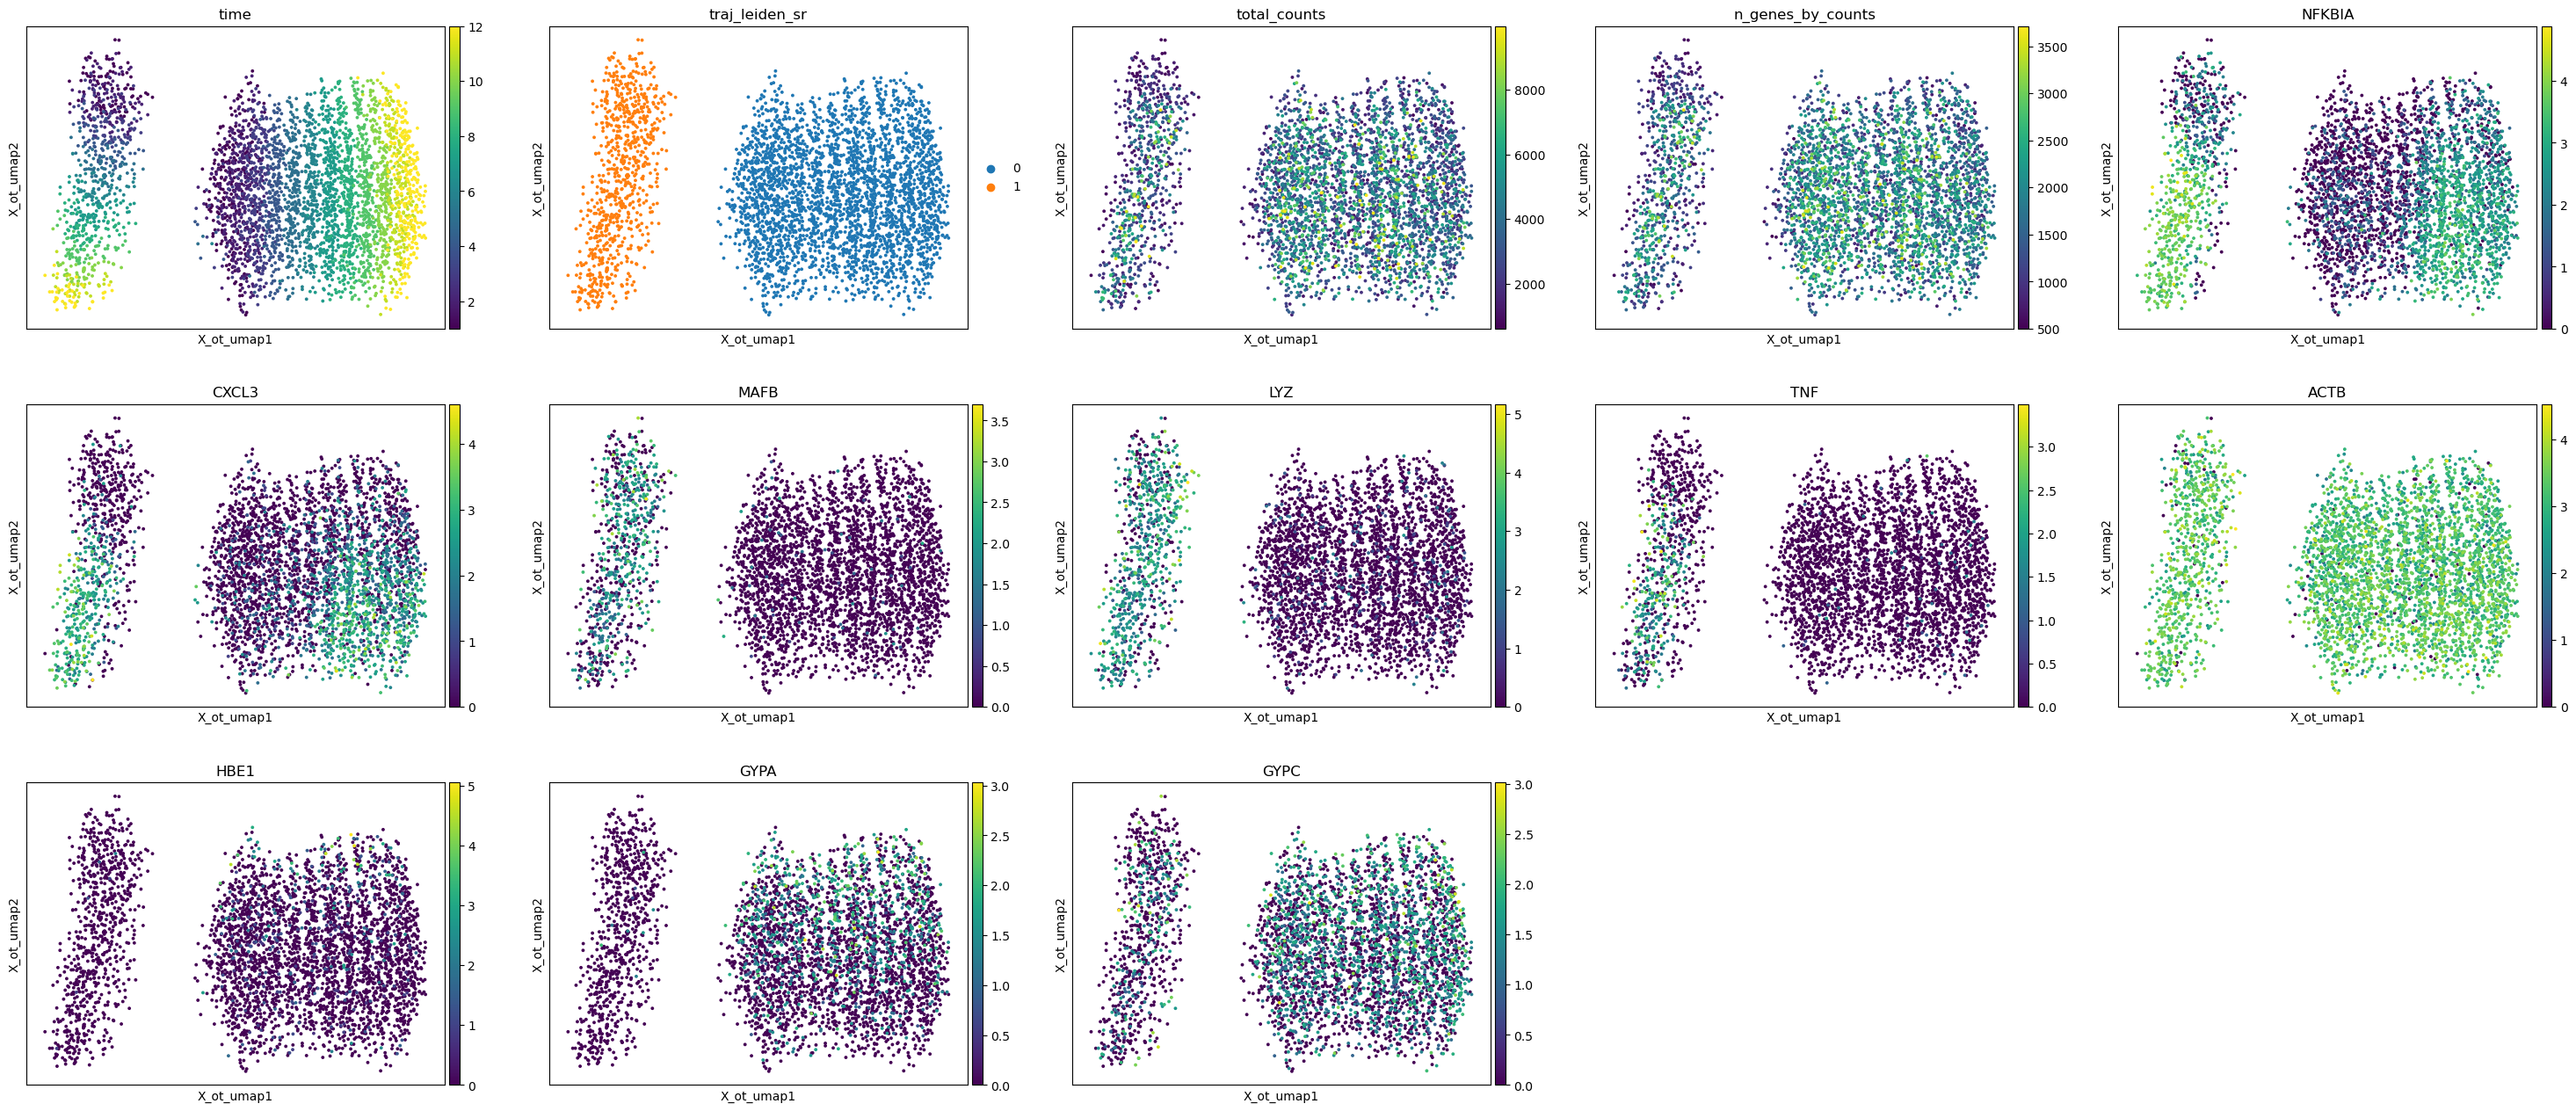

In [9]:
sc.pl.embedding(
    adata,
    basis=key,
    color=['time', 'traj_leiden_sr', 'total_counts', 'n_genes_by_counts', 'NFKBIA', 'CXCL3', 'MAFB', 'LYZ', 'TNF', 'ACTB', 'HBE1', 'GYPA', 'GYPC'],
    ncols=5,
    cmap='viridis'
)

More obvious total_counts variation, and erythroid signature is less localized now

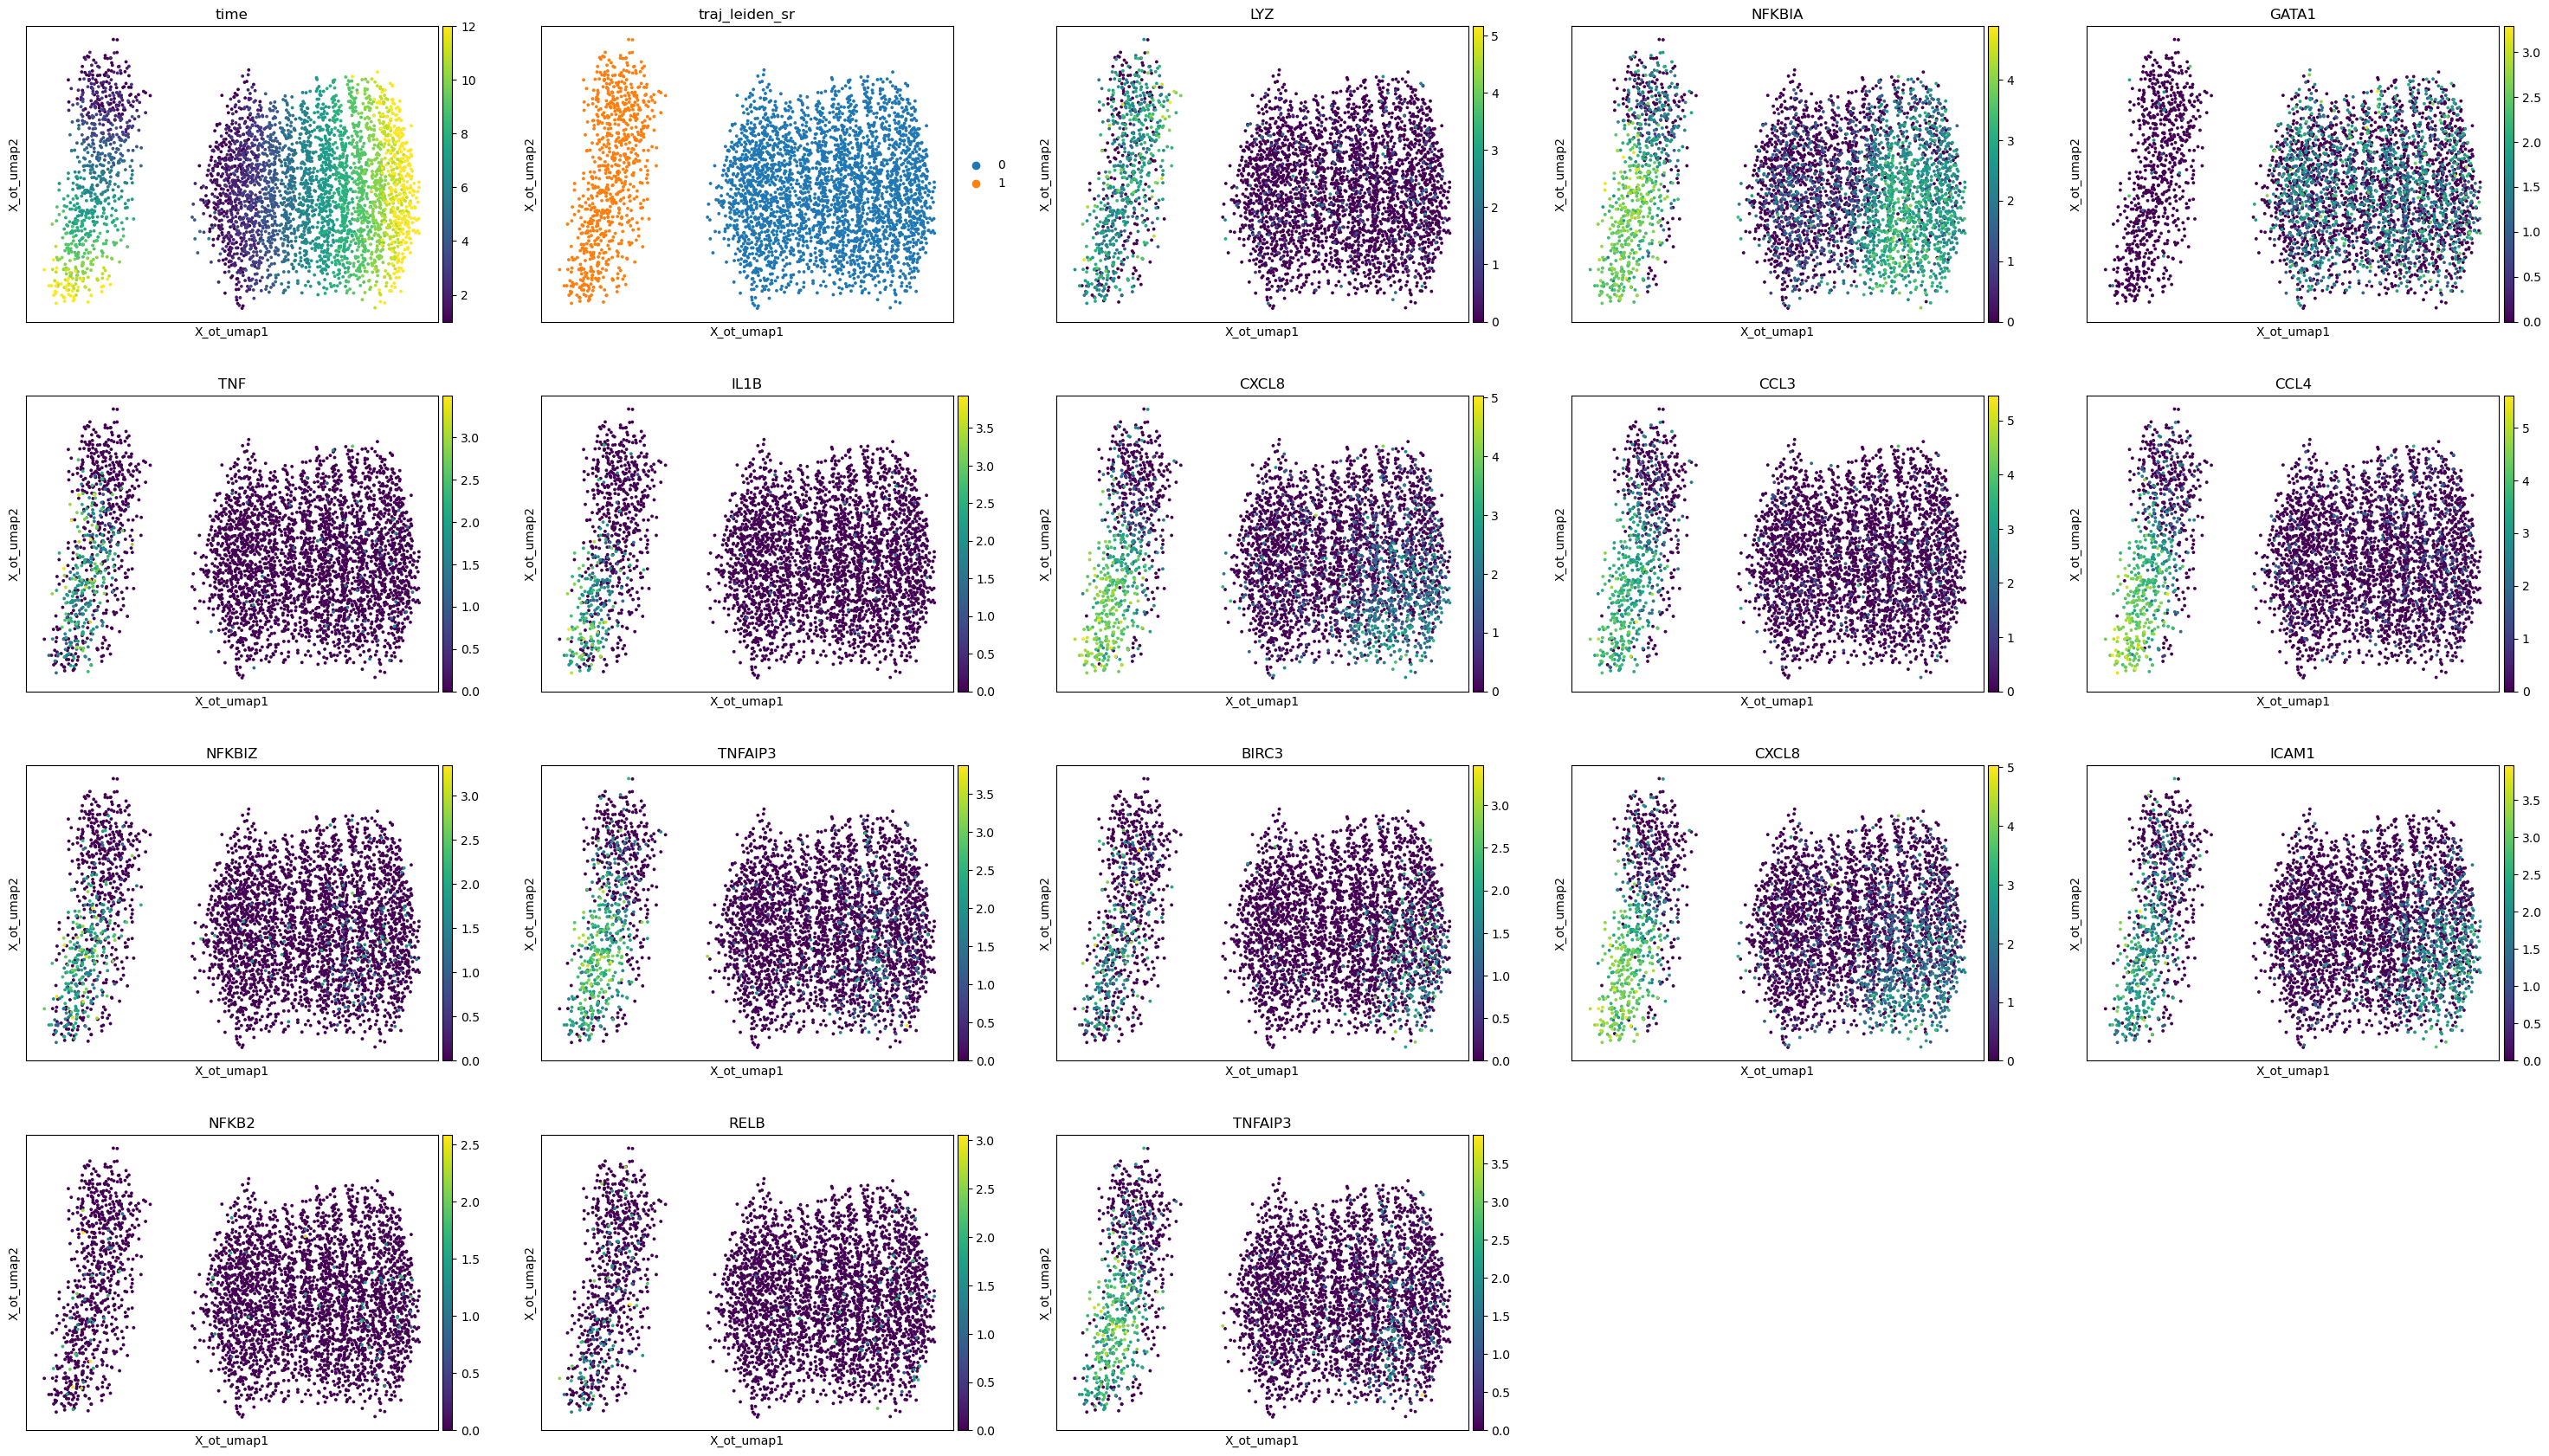

In [10]:
sc.pl.embedding(adata, basis=key, ncols=5, cmap='viridis', color=['time', 'traj_leiden_sr', 'LYZ', 'NFKBIA', 'GATA1', 
                                                                       'TNF', 'IL1B', 'CXCL8', 'CCL3', 'CCL4', 'NFKBIZ', # LPS stimulation biased genes
                                                                       'TNFAIP3', 'BIRC3', 'CXCL8', 'ICAM1', 'NFKB2', 'RELB', 'TNFAIP3'])

# Cluster trajectories

This also works, but to be fair this is particularly easy w/two distinct cell types

Terminal timepoint: 12 | n_terminal=298
Computed terminal distributions for time bin 11/12 (n=252)
Computed terminal distributions for time bin 10/12 (n=281)


Computed terminal distributions for time bin 9/12 (n=346)
Computed terminal distributions for time bin 8/12 (n=360)


Computed terminal distributions for time bin 7/12 (n=403)
Computed terminal distributions for time bin 6/12 (n=302)


Computed terminal distributions for time bin 5/12 (n=291)
Computed terminal distributions for time bin 4/12 (n=297)


Computed terminal distributions for time bin 3/12 (n=319)
Computed terminal distributions for time bin 2/12 (n=429)


Computed terminal distributions for time bin 1/12 (n=337)


Stored adata.obsm['terminal_cell_dist'] with shape (3915, 298) (sparse nnz=566455)


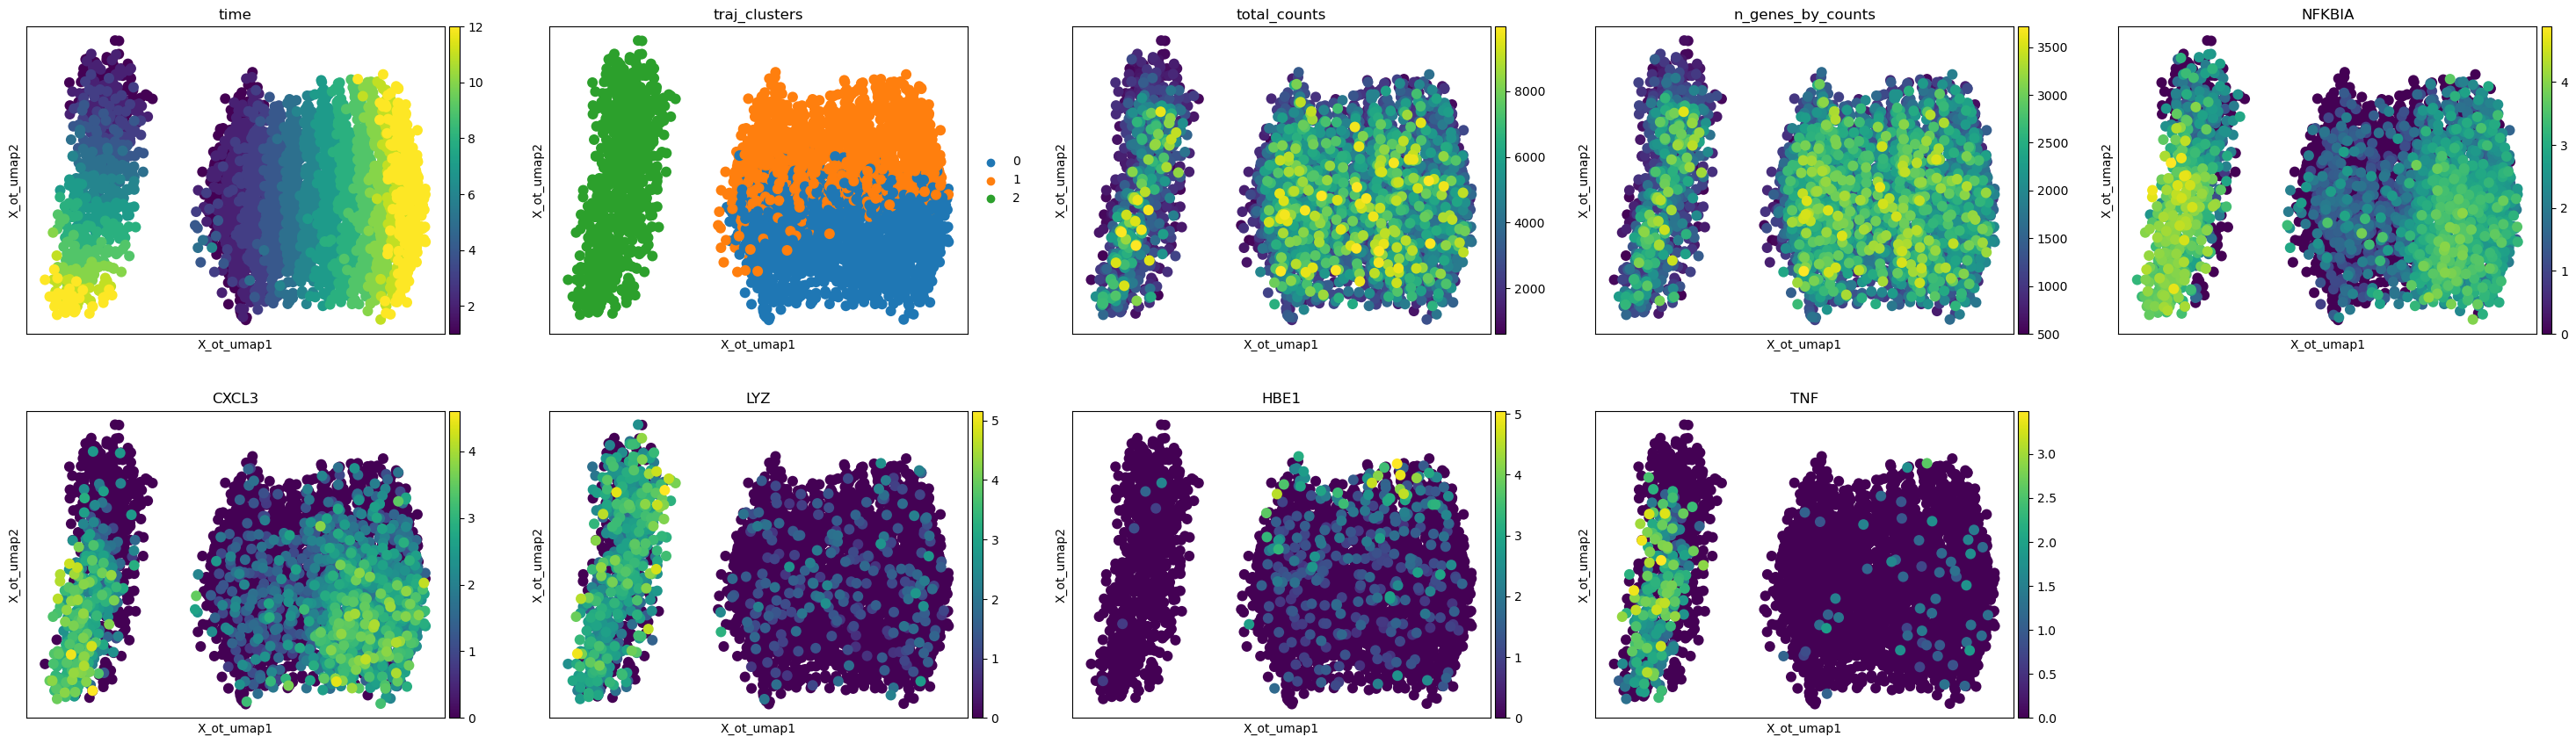

In [11]:
# Final trajectory clustering: terminal-fate-distance graph, resolution 0.6.
# These traj_clusters are propagated to the saved AnnData objects and used downstream.
CalculateTerminalFatesAcrossCells(adata_hvg, T_pruned)

W_pruned = cosine_topk_leiden_from_terminal_dist(adata_hvg, dist_key='terminal_cell_dist', topk=500)

sc.tl.leiden(
    adata_hvg,
    adjacency=W_pruned.tocsr(),
    directed=False,
    use_weights=True,
    key_added='traj_clusters',
    resolution=0.6,
    random_state=0,
)

sc.pl.embedding(
    adata_hvg,
    basis=key, size=300,
    color=['time', 'traj_clusters', 'total_counts', 'n_genes_by_counts', 'NFKBIA', 'CXCL3', 'LYZ', 'HBE1', 'TNF'],
    ncols=5,
    cmap='viridis'
)


# Calculate terminal fates & trajectory cluster mass retention

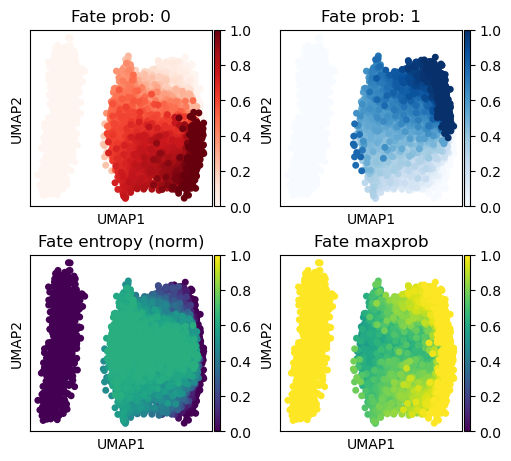

(<Figure size 500x450 with 8 Axes>,
 array([[<Axes: title={'center': 'Fate prob: 0'}, xlabel='UMAP1', ylabel='UMAP2'>,
         <Axes: title={'center': 'Fate prob: 1'}, xlabel='UMAP1', ylabel='UMAP2'>],
        [<Axes: title={'center': 'Fate entropy (norm)'}, xlabel='UMAP1', ylabel='UMAP2'>,
         <Axes: title={'center': 'Fate maxprob'}, xlabel='UMAP1', ylabel='UMAP2'>]],
       dtype=object))

In [12]:
F, fate_names = terminal_fates_from_terminal_clusters(adata_hvg, terminal_cluster_key="traj_clusters", out_key="terminal_fate_probs_traj")
fate_umap_2x2_scanpy(adata_hvg, size=100)

/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


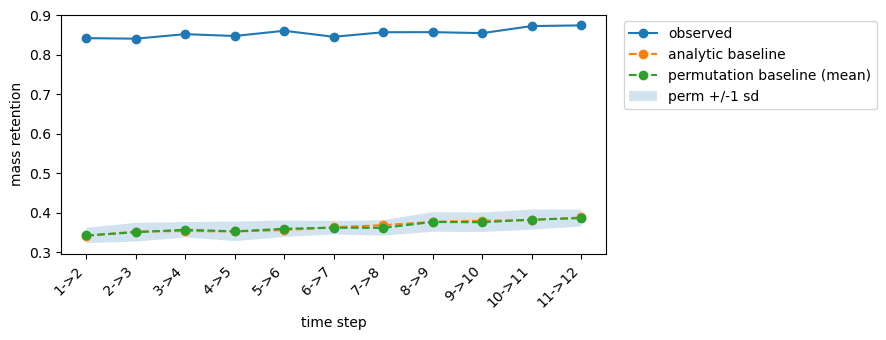

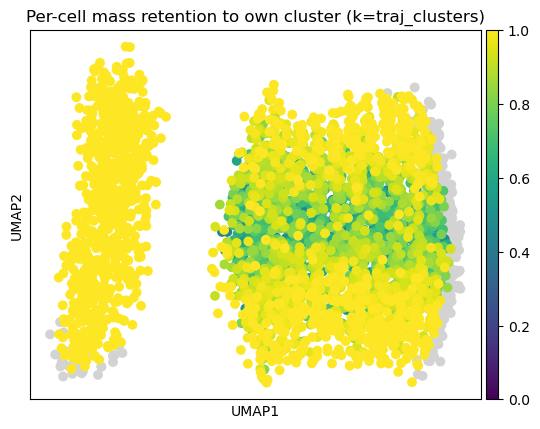

In [13]:
out = mass_retention_plots_and_umap(adata_hvg, T_pruned, 
                                    cluster_key="traj_clusters", 
                                    n_reps=50, clusters_to_plot=["0","1"], 
                                    umap_basis="umap", size=200)

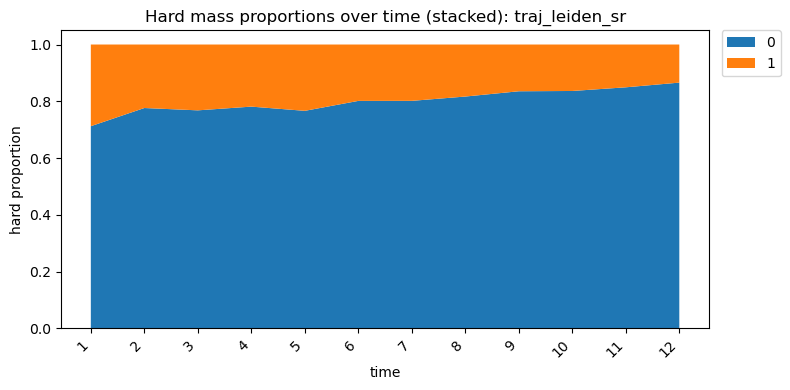

In [14]:
PlotHardClusterMassProportionsOverTime(adata_hvg, cluster_key = 'traj_leiden_sr')

In [15]:
adata.obs = adata_hvg.obs.copy()
adata.obsm = adata_hvg.obsm.copy()
adata.obsp = adata_hvg.obsp.copy()
adata.uns = adata_hvg.uns.copy()

adata.write_h5ad('../output/adata_full.chk1.h5ad')
adata_hvg.write_h5ad('../output/adata_hvg.chk1.h5ad')